In [ ]:
# Name = Nayasa
# Roll no. = 2601840005
# CAPSTONE_PROJECT

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Student_Performance.csv")

print("Dataset loaded successfully! Here are the first 5 rows:")
display(df.head())

Dataset loaded successfully! Here are the first 5 rows:


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [ ]:
# 1. Check dimensions (rows and columns)
print("Shape of dataset (Rows, Columns):", df.shape)

# 2. Check column data types and non-null counts
print("\n--- Data Info ---")
df.info()

# 3. Check for missing values
print("\n--- Missing Values ---")
print(df.isnull().sum())

# 4. Statistical summary of numerical columns
print("\n--- Statistical Summary ---")
display(df.describe())

Shape of dataset (Rows, Columns): (10000, 6)

--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB

--- Missing Values ---
Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: in

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,4.992900,69.445700,6.530600,4.583300,55.366470
std,2.589309,17.343152,1.695863,2.867348,19.257962
min,1.000000,40.000000,4.000000,0.000000,10.100000
25%,3.000000,54.000000,5.000000,2.000000,40.275000
50%,5.000000,69.000000,7.000000,5.000000,55.300000
75%,7.000000,85.000000,8.000000,7.000000,70.700000
max,9.000000,99.000000,9.000000,9.000000,100.000000


In [ ]:
# --- STEP 2: DATA CLEANING & PREPROCESSING ---

# 1. Check for duplicate rows
print("Duplicate rows before cleaning:", df.duplicated().sum())

# Drop duplicates if any exist
df = df.drop_duplicates()
print("Duplicate rows after cleaning:", df.duplicated().sum())

# 2. Encode categorical column ('Extracurricular Activities')
# Mapping 'Yes' to 1 and 'No' to 0
df['Extracurricular Activities'] = df['Extracurricular Activities'].map({'Yes': 1, 'No': 0})

# 3. Verify changes with info and first few rows
print("\n--- Cleaned Data Info ---")
df.info()

print("\nFirst 5 rows after encoding:")
display(df.head())

Duplicate rows before cleaning: 13
Duplicate rows after cleaning: 0

--- Cleaned Data Info ---
<class 'pandas.core.frame.DataFrame'>
Index: 9987 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     9987 non-null   int64  
 1   Previous Scores                   9987 non-null   int64  
 2   Extracurricular Activities        9987 non-null   int64  
 3   Sleep Hours                       9987 non-null   int64  
 4   Sample Question Papers Practiced  9987 non-null   int64  
 5   Performance Index                 9987 non-null   float64
dtypes: float64(1), int64(5)
memory usage: 546.2 KB

First 5 rows after encoding:


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,1,9,1,91.0
1,4,82,0,4,2,65.0
2,8,51,1,7,2,45.0
3,5,52,1,5,2,36.0
4,7,75,0,8,5,66.0


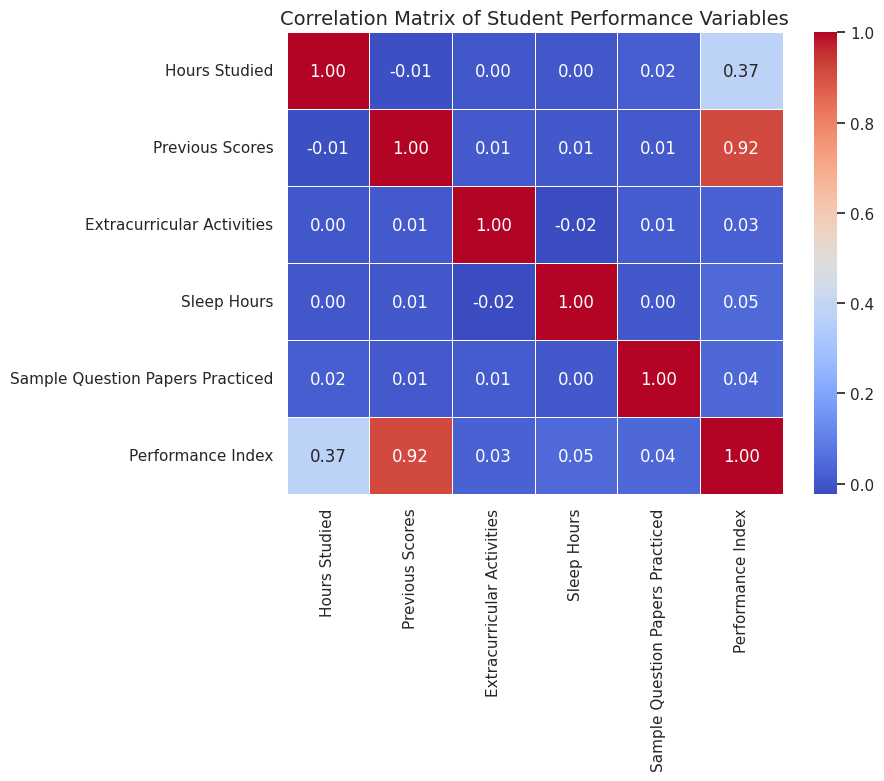

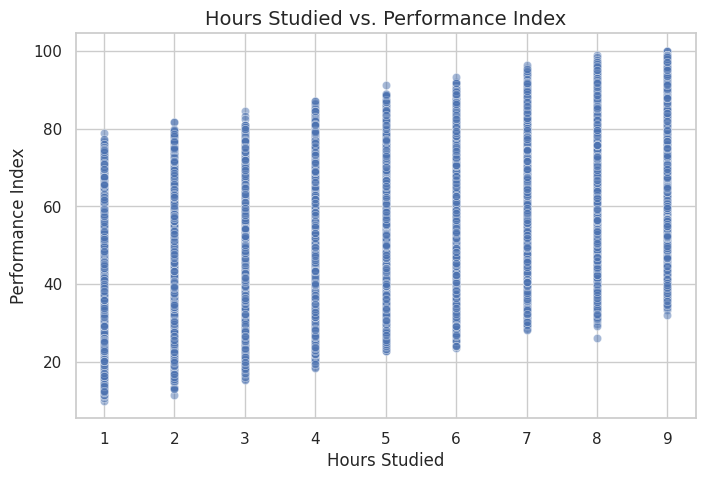

In [ ]:
# --- STEP 3: EXPLORATORY DATA ANALYSIS & VISUALISATION ---

# 1. Set the visual style for seaborn
sns.set_theme(style="whitegrid")

# 2. Plot Correlation Heatmap
plt.figure(figsize=(8, 6))
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix of Student Performance Variables", fontsize=14)
plt.show()

# 3. Plot Scatter Plot: Hours Studied vs Performance Index
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Hours Studied', y='Performance Index', data=df, alpha=0.5, color='b')
plt.title("Hours Studied vs. Performance Index", fontsize=14)
plt.xlabel("Hours Studied")
plt.ylabel("Performance Index")
plt.show()

In [ ]:
# --- STEP 4: MACHINE LEARNING MODEL BUILDING (LINEAR REGRESSION) ---
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Define Features (X) and Target variable (y)
X = df.drop('Performance Index', axis=1)
y = df['Performance Index']

# 2. Split the dataset into 80% Training and 20% Testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Initialize and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Make predictions on the test set
y_pred = model.predict(X_test)

# 5. Evaluate model performance
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("--- Model Evaluation Results ---")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R-squared ($R^2$) Score: {r2:.4f}")

# 6. Display the impact (coefficients) of each feature
coefficients = pd.DataFrame(model.coef_, X.columns, columns=['Coefficient'])
print("\n--- Model Coefficients ---")
display(coefficients)

--- Model Evaluation Results ---
Mean Squared Error (MSE): 3.9396
R-squared ($R^2$) Score: 0.9893

--- Model Coefficients ---


,Coefficient
Hours Studied,2.855999
Previous Scores,1.021757
Extracurricular Activities,0.594102
Sleep Hours,0.469701
Sample Question Papers Practiced,0.183179


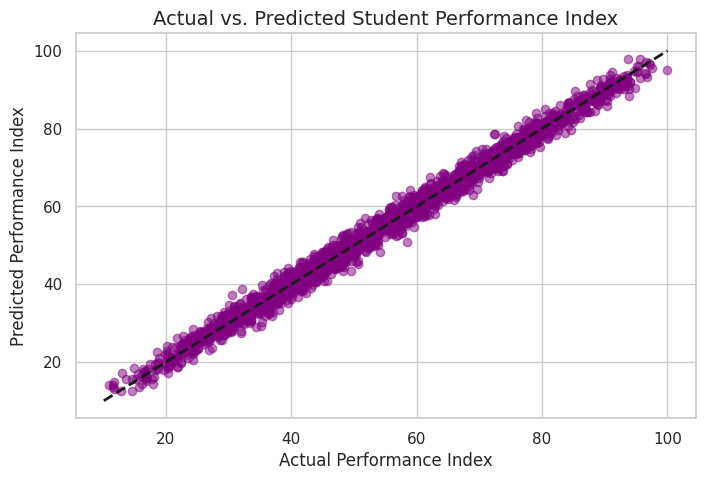

=== CAPSTONE PROJECT SUMMARY ===
Dataset Size: 9987 records, 6 features
Model Used: Linear Regression
R-squared Score: 0.9893 (indicating high predictive accuracy!)
Conclusion: Hours Studied and Previous Scores are the strongest drivers of student performance.


In [ ]:
# --- STEP 5: VISUALISING RESULTS & FINAL CONCLUSION ---

# 1. Plot Actual vs. Predicted Performance Index
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.5, color='purple')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2) # Diagonal reference line
plt.title("Actual vs. Predicted Student Performance Index", fontsize=14)
plt.xlabel("Actual Performance Index", fontsize=12)
plt.ylabel("Predicted Performance Index", fontsize=12)
plt.show()

# 2. Print Project Summary Statement for Report
print("=== CAPSTONE PROJECT SUMMARY ===")
print(f"Dataset Size: {df.shape[0]} records, {df.shape[1]} features")
print(f"Model Used: Linear Regression")
print(f"R-squared Score: {r2:.4f} (indicating high predictive accuracy!)")
print("Conclusion: Hours Studied and Previous Scores are the strongest drivers of student performance.")